In [1]:
import os
import xarray as xr
import pandas as pd
import dask
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from dask_jobqueue import PBSCluster
from dask.distributed import Client
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
import copy
import functools
import glob
import scipy

In [2]:
def get_surdat(surdat_file):
    """
    Read in CLM surface data file and pull out needed values
    
    """

    surdat = xr.open_dataset(surdat_file)

    # set actual latitude and longitude values as the dimension values
    surdat['lat'] = xr.DataArray(np.unique(surdat.LATIXY.values), dims='lsmlat')
    surdat['lon'] = xr.DataArray(np.unique(surdat.LONGXY.values), dims='lsmlon')
    surdat = surdat.swap_dims({'lsmlat': 'lat', 'lsmlon': 'lon'})

    surdat['PCT_NAT_PFT_UPDATED'] = (surdat.PCT_NAT_PFT*(surdat.PCT_NATVEG/100.0))
    surdat['PCT_CFT_UPDATED'] = (surdat.PCT_CFT*(surdat.PCT_CROP/100.0))

    out = surdat[['PCT_NAT_PFT_UPDATED', 'PCT_CFT_UPDATED']]

    lat = out.lat.data
    lon = out.lon.data
    out['dominant_pft_ind'] = xr.DataArray(
        data=999,
        dims=["lat", "lon"],
        coords=dict(
            lon=(["lon"], lon),
            lat=(["lat"], lat),
        )
    )
    out['dominant_pft'] = xr.DataArray(
        data='-'*500,
        dims=["lat", "lon"],
        coords=dict(
            lon=(["lon"], lon),
            lat=(["lat"], lat),
        )
    )

    return out

In [3]:
def get_dom_pfts(dat,threshold):
    all_pfts = np.append(dat.PCT_NAT_PFT_UPDATED.values, dat.PCT_CFT_UPDATED.values)
    non_veg = all_pfts[0]
    
    veg = all_pfts[1:]
    
    if (all_pfts.sum() >= threshold) & (non_veg <= 50):

            sum_veg = veg.sum()
            veg_prop = (veg/sum_veg)*100.0
            
            sorted_pfts = sorted(veg_prop, reverse=True)
            pft_sort = np.flip(np.argsort(veg_prop))
            
            if sorted_pfts[0] >= threshold:
                dom_pft_inds = [pft_sort[0].tolist()]
            else:
                cumul_prop = sorted_pfts[0]
                for i in range(1, len(sorted_pfts)):
                    cumul_prop = cumul_prop + sorted_pfts[i]
                    if cumul_prop >= threshold:
                        dom_pft_inds = pft_sort[:i+1].tolist()
                        break
            
            clm_pft_ind = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16]
            dom_pfts = [clm_pft_ind[i] for i in sorted(dom_pft_inds)]

    else:
        if non_veg >= threshold:
            dom_pfts = [0]
        else:
            dom_pfts = '-'
        
    return dom_pfts

In [4]:
veg_combos = {
    "Tundra": {tuple([11]),tuple(sorted([11, 12]))},
    "Boreal shrubland": {tuple([12])},
    "Boreal forest": {tuple([2]),tuple(sorted([2,11, 12])),tuple(sorted([2, 12])),tuple(sorted([2, 11]))},
    "Cold deciduous forest" : {tuple(sorted([3])),tuple(sorted([11,3])),tuple(sorted([12,3])),tuple(sorted([11,12,3]))},
    
    "Tropical rainforest" : {tuple(sorted([4]))},
    "Tropical savanna": {tuple(sorted([4,14])),tuple(sorted([14]))},
    "Subtropical savanna" : {tuple(sorted([6,14])),tuple(sorted([4,6])),tuple(sorted([4,6,14]))},

    "Grasslands" : {tuple(sorted([13])),tuple(sorted([13,15])),tuple(sorted([13,14])),tuple(sorted([13,14,15]))},
    "Shrublands" :  {tuple(sorted([10,13])),tuple(sorted([10,14])),tuple(sorted([10,13,14])),tuple(sorted([10,13,15])),tuple(sorted([10,14,15])),tuple(sorted([10,13,14,15]))},
    
    "Temperate mixed forest" :  {tuple(sorted([7])),
                                           tuple(sorted([1,7])),
                                           tuple(sorted([7,13])),
                                           tuple(sorted([7,14])),
                                           tuple(sorted([7,15])),
                                           tuple(sorted([1,7,13])),
                                           tuple(sorted([1,7,14])),
                                           tuple(sorted([1,7,15])),
                                           tuple(sorted([1,7,13,15])),
                                           tuple(sorted([1,7,14,15])),
                                           tuple(sorted([1,7,13,14])),
                                           tuple(sorted([7,13,14])),
                                           tuple(sorted([7,13,15])),
                                           tuple(sorted([7,14,15])),
                                           tuple(sorted([7,13,14,15])),
                                           tuple(sorted([1,7,13,14,15]))},

    "Evergreen forest" : {tuple(sorted([1])),
                        tuple(sorted([1,2])),
                        tuple(sorted([1,13])),
                        tuple(sorted([1,14])),
                        tuple(sorted([1,15])),
                        tuple(sorted([1,2,13])),
                        tuple(sorted([1,2,14])),
                        tuple(sorted([1,2,15])),
                        tuple(sorted([1,13,14])),
                        tuple(sorted([1,13,15])),
                        tuple(sorted([1,14,15])),
                        tuple(sorted([1,2,13,14])),
                        tuple(sorted([1,2,13,15])),
                        tuple(sorted([1,2,14,15])),
                        tuple(sorted([1,13,14,15])),
                        tuple(sorted([1,2,13,14,15]))},
    
    "Boreal mixed forest" : { tuple(sorted([8])),
               tuple(sorted([2,8])),
               tuple(sorted([8,12])),
               tuple(sorted([8,13])),
               tuple(sorted([8,15])),
               tuple(sorted([2,8,12])),
               tuple(sorted([2,8,13])),
               tuple(sorted([2,8,15])),
               tuple(sorted([8,12,13])),
               tuple(sorted([8,12,15])),
               tuple(sorted([8,13,15])),
               tuple(sorted([2,8,13,15])),
               tuple(sorted([2,8,12,13])),
               tuple(sorted([2,8,12,15])),
               tuple(sorted([2,8,12,13,15])),
              },

    "Temperate woodland" : {tuple(sorted([5])),
                    tuple(sorted([5,13])),
                    tuple(sorted([5,14])),
                    tuple(sorted([5,15])),
                    tuple(sorted([5,13,14])),
                    tuple(sorted([5,13,15])),
                    tuple(sorted([5,14,15])),
                    tuple(sorted([5,13,14,15]))}

}


### Create Biome masks

In [29]:
## Surface datasets
surdat_dir = "/glade/campaign/cesm/cesmdata/inputdata/lnd/clm2/surfdata_esmf/"
surdat_2deg = os.path.join(surdat_dir, "ctsm5.3.0", "surfdata_1.9x2.5_hist_1850_16pfts_c240926.nc")
surfdat = get_surdat(surdat_2deg)

In [30]:
filename = '/glade/work/linnia/CLM6-PPE/BNF_v2.n01_ctsm5.3.012_transient_SP/run/BNF_v2.n01_ctsm5.3.012_transient_SP_2.clm2.h1.2000-02-01-00000.nc'
ds_sp = xr.open_dataset(filename)
landfrac = ds_sp.landfrac

In [31]:
# Find PFTs that sum to >75% of vegetated portion of gridcell
threshold=75

lats = surfdat.lat.values
lons = surfdat.lon.values

dom_pft_data = np.empty((len(lats), len(lons)), dtype=object)

for i, lat in enumerate(lats):
    for j, lon in enumerate(lons):
        if landfrac.sel(lat=lat,method='nearest').sel(lon=lon,method='nearest')>0.6:
            dat = surfdat.sel(lat=lat, method='nearest').sel(lon=lon, method='nearest')
            dom_pft_data[i, j] = get_dom_pfts(dat, threshold)

# Store in an xarray Dataset
ds_out = xr.Dataset(
    {"dom_pfts": (["lat", "lon"], dom_pft_data)},
    coords={"lat": lats,"lon": lons}
    )


In [32]:
# create dataset of 2D biome masks
biome_masks = {}
lat_values = ds_out.lat.values
lon_values = ds_out.lon.values

for biome_name, pft_combos in veg_combos.items():
    # Create a mask for the biome
    biome_mask = np.zeros((len(lat_values), len(lon_values)), dtype=int)  

    for i, lat in enumerate(lat_values):
        for j, lon in enumerate(lon_values):
            dom_pfts = ds_out.dom_pfts.values[i, j] 
            
            if dom_pfts is not None:
                sorted_pfts = tuple(sorted(dom_pfts))  
                if sorted_pfts in pft_combos:
                    biome_mask[i, j] = 1  # Mark as 1 (true)

    biome_masks[biome_name] = (["lat", "lon"], biome_mask)

biome_ds = xr.Dataset(biome_masks, coords={"lat": lat_values, "lon": lon_values})
biome_ds['Boreal shrubland'] = biome_ds['Boreal shrubland'].where(biome_ds['lat'] >= 51, 0)


In [33]:
biome_names = ['Tropical rainforest','Tropical savanna','Subtropical savanna','Grasslands','Shrublands','Temperate woodland','Temperate mixed forest',
               'Evergreen forest','Boreal forest','Cold deciduous forest','Boreal mixed forest','Boreal shrubland','Tundra']

# Create an empty array for the final categorical map
lat_values = biome_ds.lat.values
lon_values = biome_ds.lon.values
biome_map = np.zeros((len(lat_values), len(lon_values)))  # Default to 0

# Assign unique values to each biome
for idx, biome in enumerate(biome_names, start=1):
    biome_mask = biome_ds[biome].values
    biome_map[biome_mask == 1] = idx  # Assign unique integer value


### Write file

In [34]:
# use whittaker biomes file as template
wfile='/glade/u/home/djk2120/ctsm6_ppe/biomes/whit/whitkey.nc'
whit=xr.open_dataset(wfile)

In [35]:
biome_names = ['Other','Tropical rainforest','Tropical savanna','Subtropical savanna','Grasslands','Shrublands','Temperate woodland','Temperate mixed forest',
               'Evergreen forest','Boreal forest','Cold deciduous forest','Boreal mixed forest','Boreal shrubland','Tundra']

ds_biome_maps = whit.copy()
ds_biome_maps['biomes'] = (('lat', 'lon'), biome_map)
ds_biome_maps = ds_biome_maps.assign_coords(biome_names=biome_names)
ds_biome_maps = ds_biome_maps.drop_vars('biome_fg')
ds_biome_maps = ds_biome_maps.drop_vars('biome_name')

In [36]:
ds_biome_maps.attrs['script'] = '/glade/u/home/linnia/CLM6-PPE/biomes/create_biome_masks.ipynb'
del ds_biome_maps.attrs['climo']
del ds_biome_maps.attrs['case']

In [37]:
ds_biome_maps.to_netcdf('biome_masks.nc')

### Plot

In [38]:
ds_biome_maps = xr.open_dataset('biome_masks.nc')

In [39]:
biome_names = ['Other','Tropical rainforest','Tropical savanna','Subtropical savanna','Grasslands','Shrublands','Temperate woodland','Temperate mixed forest',
               'Evergreen forest','Boreal forest','Cold deciduous forest','Boreal mixed forest','Boreal shrubland','Tundra']


In [40]:
from matplotlib.colors import ListedColormap, BoundaryNorm

N = len(biome_names)
bounds = np.arange(N+1)
norm = BoundaryNorm(bounds, N)

colors = [
    "grey",
    "#004D19","#5D9945","darkseagreen",  # (tropic, tropic, savanna,)
    "#DECAA7", "#D2B48C", # (grasslands, shrublands)
    "#859457","#A1AF78","lightblue","cadetblue","teal",# (mixed decid, conifer, larch)
    "thistle","lavenderblush","lavender" # (boreal forest, aspen, boreal shrub, tundra)
]

cmap = ListedColormap(colors, name="earth_biomes_19")

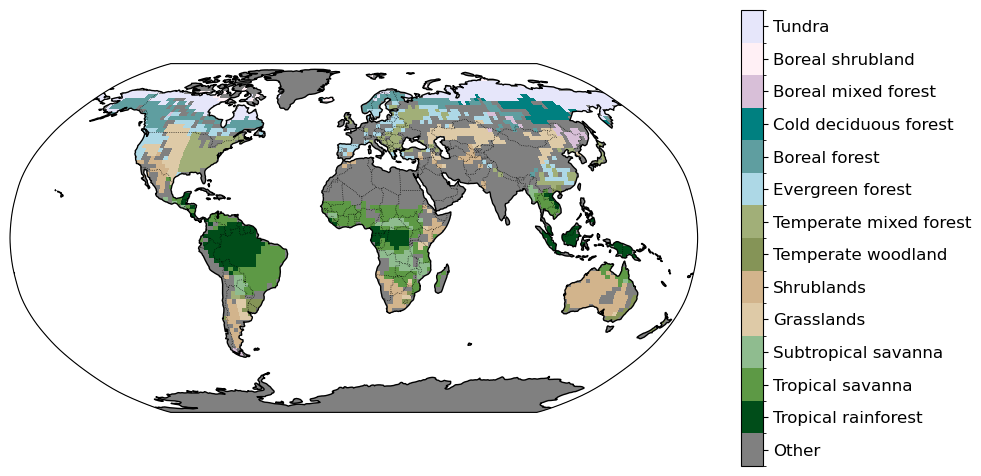

In [41]:
lat_values = ds_out.lat.values
lon_values = ds_out.lon.values

fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.Robinson()})
ocean = ax.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '110m',facecolor='white'))
mesh = ax.pcolormesh(lon_values, lat_values, ds_biome_maps.biomes, transform=ccrs.PlateCarree(), cmap=cmap, norm=norm, shading='auto')
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5)


cbar = plt.colorbar(mesh,ticks=np.arange(N) + 0.5,shrink=0.8)
cbar.set_ticklabels(np.concatenate([np.array(biome_names)]),fontsize=12)

plt.tight_layout()
plt.savefig('biome_map.png',dpi = 300)

### Create crop mask

### Calculate pxb biome landarea file

In [16]:
def gc_to_pft():
    ''' can be used to xfer gc data to pft 
        via da.stack({'gc':['lat','lon']}).isel(gc=ix)
        '''
    d='/glade/derecho/scratch/slevis/archive/ctsm53017_f19_BNF_hist/lnd/hist/'
    files=sorted(glob.glob(d+'*h1*'))
    tmp=xr.open_dataset(files[0])
    nlon=len(tmp.lon)
    nlat=len(tmp.lat)
    ix=((tmp.pfts1d_jxy-1)*nlon+tmp.pfts1d_ixy-1).astype(int)
    return ix

In [63]:
#loading files
wfile='biome_masks.nc'
sud=xr.open_dataset(wfile)

#loading files
d='/glade/derecho/scratch/linnia/ctsm5.3.065_transient_lhc0000/run/'
sgfiles=sorted(glob.glob(d+'*h1*'))
sg=xr.open_dataset(sgfiles[0])
cfile='/glade/u/home/djk2120/ctsm6_ppe/sparsegrid/pftmean/ctsm53017_f19_BNF_sgpft_cribsheet.nc'
crib=xr.open_dataset(cfile)
afile='/glade/u/home/djk2120/ctsm6_ppe/sparsegrid/pftmean/lapft_ctsm53017.nc'
lapft=xr.open_dataset(afile).lapft

In [65]:
#labeling all the patches by pxb
ix=gc_to_pft()
p=crib.pfts1d_itype_veg
pu=xr.DataArray(np.unique(p),dims='vegtype')
b=sud.biomes.stack({'gc':['lat','lon']}).isel(gc=ix)
bu=xr.DataArray(np.unique(b),dims='biome')
pxbmap=(b==bu)&(p==pu)

In [66]:
#accumulating all the fg patches into sg cohorts
good=(crib.not_antarctica)
g=crib.sgpft_cribsheet
g.name='sgpft'
x=(pxbmap*lapft.where(good)).groupby(g).sum()

In [67]:
s=[len(x[d]) for d in x.dims]
s[0]=len(sg.pft)
dims=[d for d in x.dims]
dims[0]='pft'
xout=xr.DataArray(np.zeros(s),dims=dims)
xout[x.sgpft,:,:,:]=x
xout['year']=x.year

In [68]:
dsout=xr.Dataset()
dsout['lapxb_sg']=xout
#dsout['pft_name']=pft_abbrevs()
#biomes=['Other',*sud.biome_names.values] #hacky, will break
dsout['biome_name']=xr.DataArray(sud.biome_names.values,dims='biome')
for v in ['itype_veg','lat','lon']:
    dsout['pfts1d_'+v]=sg['pfts1d_'+v]
dsout.attrs={'script':'/glade/u/home/linnia/CLM6-PPE/biomes/create_biome_masks.ipynb',
             'biomes':wfile,
             'lapft':afile,
             'patch_similarity':cfile}
file='/glade/u/home/linnia/CLM6-PPE/utils/lapxb_sg_biomes_ctsm53065.nc'
dsout.to_netcdf(file)

In [ ]:
# test

In [73]:
lapxb=dsout.lapxb_sg
d='/glade/derecho/scratch/linnia/ctsm5.3.065_transient_lhc0000/run/'
sgfiles=sorted(glob.glob(d+'*.h1a.*'))
sg=xr.open_dataset(sgfiles[-2])

### Calculate biome land area

In [20]:
d='/glade/derecho/scratch/linnia/ctsm5.3.065_transient_lhc0000/run/'
sgfiles=sorted(glob.glob(d+'*h1*'))
sg=xr.open_dataset(sgfiles[0])

In [21]:
#loading files
sfile='/glade/u/home/djk2120/ctsm6_ppe/sparsegrid/sgmap_retrain_h0.nc'
sgmap=xr.open_dataset(sfile)
wfile='biome_masks.nc'
sud=xr.open_dataset(wfile)

In [22]:
#random full grid file
d='/glade/derecho/scratch/linnia/ctsm5.3.065_transient_coldstart_2degfull_pSASU_lhc0000/run/'
files=sorted(glob.glob(d+'*h0a*'))
tmp=xr.open_dataset(files[0])
la=(tmp.area*tmp.landfrac).where(tmp.lat>-60) #nix antarctica

In [23]:
#calc biome-cclass intersection, accumulate to sparsegrid
b=sud.biomes
bu=xr.DataArray(np.unique(b),dims='biome')
g=sgmap.cclass
g.name='gridcell'
la_biome=(la*(b==bu)).groupby(g).sum()
la_biome.attrs={'long_name':'total represented area',
                'units':'km2'}

In [24]:
#write to file
dsout=xr.Dataset()
dsout.attrs={'script':'/glade/u/home/linnia/CLM6-PPE/biomes/create_biome_masks.ipynb',
             'biomes':wfile,
             'similarity':sfile}
dsout['landarea_biome']=la_biome
dsout['biome_name']=xr.DataArray(sud.biome_names.values,dims='biome')
fout='lasg_sudoku_ctsm53065.nc'
dsout.to_netcdf(fout)

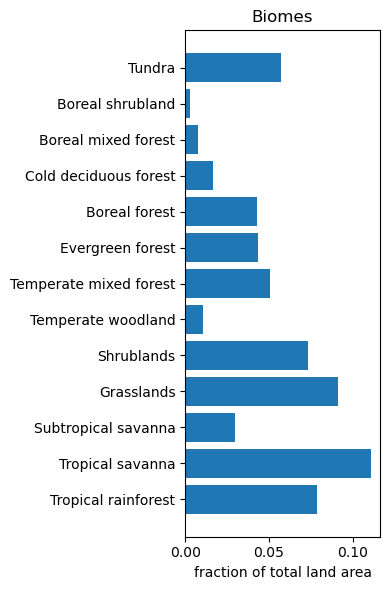

In [25]:
x=la_biome.sum(dim='gridcell')
ixb=range(1,14)
plt.figure(figsize=[4,6])
plt.barh(range(13),x.isel(biome=ixb)/x.sum())
plt.yticks(range(13),dsout.biome_name.isel(biome=ixb).values)
plt.xlabel('fraction of total land area')
plt.title('Biomes');
plt.tight_layout()
plt.savefig('biome_landarea.png')

In [26]:
#how many SGs are utilized in the non-other biomes?
((la_biome.isel(biome=ixb)>0).sum(dim='biome')>0).sum()

<xarray.DataArray ()> Size: 8B
array(296)

### Calculate arctic/nonarctic land area for SOMC

In [2]:
#loading files
sfile='/glade/u/home/djk2120/ctsm6_ppe/sparsegrid/sgmap_retrain_h0.nc'
sgmap=xr.open_dataset(sfile)
sud = xr.open_dataset('SOMC_arctic_masks.nc')

In [3]:
#random full grid file
d='/glade/derecho/scratch/linnia/ctsm5.3.065_transient_coldstart_2degfull_pSASU_lhc0000/run/'
files=sorted(glob.glob(d+'*h0a*'))
tmp=xr.open_dataset(files[0])
la=(tmp.area*tmp.landfrac).where(tmp.lat>-60) #nix antarctica

In [22]:
#calc biome-cclass intersection, accumulate to sparsegrid
b=sud.mask
bu=xr.DataArray(np.unique(b),dims='biome')
g=sgmap.cclass
g.name='gridcell'
la_biome=(la*(b==bu)).groupby(g).sum()
la_biome.attrs={'long_name':'total represented area',
                'units':'km2'}

In [26]:
#write to file
dsout=xr.Dataset()
dsout['landarea_biome']=la_biome
dsout['biome_name']=xr.DataArray(['nonarctic','arctic'],dims='biome')
fout='lasg_arctic_ctsm53065.nc'
dsout.to_netcdf(fout)

In [31]:
dsout.landarea_biome.isel(biome=1).sum()/la.sum()

<xarray.DataArray ()> Size: 4B
array(0.19631217, dtype=float32)
Coordinates:
    time     datetime64[ns] 8B ...